# Notebook 11 — Autoencoders and Unsupervised Deep Learning

**Deep Learning with TensorFlow | Beginner to Intermediate**

This notebook introduces neural networks that learn useful representations without requiring class labels. We will build deterministic autoencoders, sparse and denoising autoencoders, and a Variational Autoencoder (VAE). We will then use reconstruction error as one possible signal for anomaly detection in a synthetic gene-expression dataset.

> **Scope note:** The dataset is synthetic and designed for teaching. It is not real gene-expression data and must not be interpreted as biological or clinical evidence.

## Learning objectives

By the end of this notebook, you should be able to:

1. Explain the encoder, decoder, bottleneck, and latent representation.
2. Formulate reconstruction objectives and distinguish MSE from binary cross-entropy.
3. Build and evaluate a dense autoencoder with the Keras Functional API.
4. Explain sparsity and train a sparse autoencoder.
5. Train a denoising autoencoder using corrupted inputs and clean targets.
6. Explain the probabilistic latent space and KL-divergence regularization in a VAE.
7. Calibrate an anomaly threshold using validation data only.
8. Identify limitations of reconstruction-based anomaly detection.

## Notebook map

- Part I — Representation learning and reconstruction objectives
- Part II — Synthetic data and leakage-safe preprocessing
- Part III — Basic, sparse, and denoising autoencoders
- Part IV — Variational Autoencoders
- Part V — Reconstruction-based anomaly detection
- Part VI — Exercises, takeaways, and references

## 1. What is unsupervised representation learning?

In supervised learning, a model receives examples and target labels. In unsupervised representation learning, the model is trained to discover structure in the input data without class labels.

An autoencoder is trained to reproduce its input. This self-supervised objective encourages the network to retain information that is useful for reconstruction. It does **not** guarantee that the latent variables correspond to known biological mechanisms or clinically meaningful concepts.

### The encoder–decoder framework

Let an input sample be $\mathbf{x} \in \mathbb{R}^{d}$. An encoder maps it to a lower-dimensional representation:

$$
\mathbf{z} = f_{\theta}(\mathbf{x})
$$

A decoder maps the representation back to the input space:

$$
\hat{\mathbf{x}} = g_{\phi}(\mathbf{z})
$$

The model learns parameters $\theta$ and $\phi$ by minimizing a reconstruction objective.

### Conceptual architecture

```text
Input x  ──►  Encoder fθ  ──►  Latent representation z  ──►  Decoder gφ  ──►  Reconstruction x_hat
  d features                  k features (k < d)                         d features
```

The bottleneck limits the information capacity of the representation. If the network is too powerful or the bottleneck is not constrained, it may learn a near-identity mapping rather than a useful compressed representation.

## 2. Reconstruction objectives

### Mean squared error

For a batch of $N$ samples and $d$ features, mean squared error (MSE) is

$$
\mathcal{L}_{\mathrm{MSE}} = \frac{1}{Nd}\sum_{i=1}^{N}\sum_{j=1}^{d}(x_{ij}-\hat{x}_{ij})^2
$$

MSE is a common choice for continuous-valued features. Large errors receive a quadratic penalty, so outliers can have substantial influence.

### Mean absolute error

$$
\mathcal{L}_{\mathrm{MAE}} = \frac{1}{Nd}\sum_{i=1}^{N}\sum_{j=1}^{d}|x_{ij}-\hat{x}_{ij}|
$$

MAE is less sensitive to large individual errors than MSE. The choice should reflect the data scale and the cost of different reconstruction errors.

### Binary cross-entropy

For binary inputs or appropriately scaled values in $[0,1]$, a Bernoulli reconstruction model may use binary cross-entropy:

$$
\mathcal{L}_{\mathrm{BCE}} = -\frac{1}{Nd}\sum_{i,j}\left[x_{ij}\log \hat{x}_{ij}+(1-x_{ij})\log(1-\hat{x}_{ij})\right]
$$

Do not use a sigmoid output with binary cross-entropy automatically for arbitrary standardized, continuous-valued data. In this notebook, the synthetic expression features are standardized and can be negative, so the decoder uses a **linear output** and MSE-based reconstruction losses.

## 3. Undercomplete, sparse, and denoising autoencoders

### Undercomplete autoencoder

An undercomplete autoencoder uses a latent dimension smaller than the input dimension. For example, mapping 48 features to 8 latent variables creates a dimensionality bottleneck.

### Sparse autoencoder

A sparse autoencoder encourages most latent activations to be close to zero. One approach adds an activity penalty to the reconstruction objective:

$$
\mathcal{L}_{\mathrm{sparse}} = \mathcal{L}_{\mathrm{reconstruction}} + \lambda \|\mathbf{z}\|_1
$$

Here, $\lambda$ controls the sparsity penalty. Too much regularization can prevent the model from retaining enough information.

### Denoising autoencoder

A denoising autoencoder receives a corrupted input $\tilde{\mathbf{x}}$ but is trained to reconstruct the original clean sample $\mathbf{x}$:

$$
\tilde{\mathbf{x}} = \mathbf{x} + \boldsymbol{\epsilon}, \qquad \boldsymbol{\epsilon}\sim\mathcal{N}(0,\sigma^2 I)
$$

$$
\mathcal{L}_{\mathrm{denoise}} = \mathbb{E}\left[\|\mathbf{x}-g_{\phi}(f_{\theta}(\tilde{\mathbf{x}}))\|_2^2\right]
$$

This objective encourages representations that are less sensitive to the particular corruption process used during training.

## 4. Variational Autoencoders (VAEs)

A deterministic autoencoder maps each input to one latent vector. A VAE instead learns a probability distribution over latent representations, commonly a diagonal Gaussian:

$$
q_{\phi}(\mathbf{z}|\mathbf{x}) = \mathcal{N}\left(\boldsymbol{\mu}_{\phi}(\mathbf{x}),\operatorname{diag}(\boldsymbol{\sigma}_{\phi}^{2}(\mathbf{x}))\right)
$$

The encoder predicts $\boldsymbol{\mu}$ and $\log\boldsymbol{\sigma}^{2}$. A latent vector is sampled using the reparameterization trick:

$$
\mathbf{z}=\boldsymbol{\mu}+\boldsymbol{\sigma}\odot\boldsymbol{\epsilon},\qquad \boldsymbol{\epsilon}\sim\mathcal{N}(0,I)
$$

The decoder reconstructs the input from this sampled latent vector.

### VAE objective: reconstruction plus KL divergence

A common minimization objective is the negative evidence lower bound (negative ELBO):

$$
\mathcal{L}_{\mathrm{VAE}} = \mathcal{L}_{\mathrm{reconstruction}} + \beta D_{\mathrm{KL}}\left(q_{\phi}(\mathbf{z}|\mathbf{x})\,\|\,p(\mathbf{z})\right)
$$

For a standard normal prior $p(\mathbf{z})=\mathcal{N}(0,I)$ and a diagonal Gaussian encoder:

$$
D_{\mathrm{KL}} = -\frac{1}{2}\sum_{j=1}^{k}\left(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2\right)
$$

The coefficient $\beta$ controls the strength of the regularization. A VAE is not simply an autoencoder with random noise: the probabilistic encoder and KL term shape the latent distribution and enable sampling from a prior.

## 5. Imports and reproducibility

We use TensorFlow/Keras for neural networks, NumPy/Pandas for data handling, Matplotlib for visualization, and scikit-learn for scaling and evaluation metrics.

In [1]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
)

SEED = 42
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)

print("TensorFlow version:", tf.__version__)
print("Keras version:", keras.__version__ if hasattr(keras, "__version__") else "bundled Keras")
print("NumPy version:", np.__version__)

TensorFlow version: 2.21.0
Keras version: 3.15.1
NumPy version: 2.4.6


## 6. Create a synthetic gene-expression-like dataset

We generate continuous features from a small number of hidden factors, add feature-specific offsets and noise, and call the resulting columns `gene_00`, `gene_01`, and so on. The hidden factors are used only to generate the data; they are not labels and are not supplied to the autoencoder.

The benchmark contains separate normal training, validation, and test samples. Artificial anomalies are added **only** to the test set. This provides a controlled way to evaluate reconstruction-based anomaly detection while keeping the model training process unsupervised.

In [2]:
N_FEATURES = 48
N_FACTORS = 5

# Fixed synthetic data-generating parameters shared across splits.
loadings = rng.normal(0.0, 0.75, size=(N_FEATURES, N_FACTORS))
gene_offsets = rng.normal(0.0, 0.35, size=N_FEATURES)


def generate_normal_expression(n_samples, random_state):
    """Generate continuous, correlated, gene-expression-like observations."""
    local_rng = np.random.default_rng(random_state)
    factors = local_rng.normal(size=(n_samples, N_FACTORS))
    linear_signal = factors @ loadings.T
    nonlinear_signal = 0.20 * np.sin(
        factors[:, [0]] * loadings[None, :, 0]
    )
    noise = local_rng.normal(0.0, 0.40, size=(n_samples, N_FEATURES))
    return (linear_signal + nonlinear_signal + noise + gene_offsets).astype("float32")


X_train_raw = generate_normal_expression(1600, SEED + 1)
X_val_raw = generate_normal_expression(350, SEED + 2)
X_test_normal_raw = generate_normal_expression(350, SEED + 3)

print("Training (normal):", X_train_raw.shape)
print("Validation (normal):", X_val_raw.shape)
print("Test normal:", X_test_normal_raw.shape)

Training (normal): (1600, 48)
Validation (normal): (350, 48)
Test normal: (350, 48)


In [3]:
feature_names = [f"gene_{i:02d}" for i in range(N_FEATURES)]
expression_df = pd.DataFrame(X_train_raw, columns=feature_names)

print("Training data preview:")
display(expression_df.head())
print("\nDescriptive statistics for the first eight features:")
display(expression_df.iloc[:, :8].describe().T)

Training data preview:


,gene_00,gene_01,gene_02,gene_03,gene_04,gene_05,gene_06,gene_07,gene_08,gene_09,...,gene_38,gene_39,gene_40,gene_41,gene_42,gene_43,gene_44,gene_45,gene_46,gene_47
0,1.533023,0.407571,-1.721259,-0.736003,0.779824,-0.862995,-0.133241,0.990146,1.316542,-1.248390,...,1.950626,0.294192,3.536196,0.138781,0.387027,0.435204,0.259005,1.296800,-0.790947,0.221180
1,-2.170812,-2.485778,-0.124846,-1.914110,-0.413315,-0.409751,2.244327,2.966418,1.796484,-0.207251,...,-0.299380,-1.437577,-1.807201,-0.825417,1.560613,0.945857,0.134502,0.392480,-2.305931,-0.634704
2,0.618895,-0.312878,-0.516638,-1.174720,-0.020298,-0.867851,1.681550,1.356554,1.718924,-1.011711,...,2.432404,-0.466004,1.517465,0.724110,1.002295,0.640645,-1.099070,-0.855266,-1.277209,0.732699
3,1.753722,-0.204489,-1.303004,-0.758704,1.823165,-0.590838,-0.474083,-0.155582,-0.044430,-1.715424,...,-0.021113,-0.038095,-0.407697,-0.695114,1.005365,0.948444,1.199707,-0.479222,0.049284,1.470429
4,2.995935,0.245286,-0.349578,-0.777440,-0.401672,-2.583658,2.318294,2.583486,2.454622,-1.404476,...,5.072521,-0.356628,2.578912,1.470507,2.894091,0.226092,-1.232416,-2.533347,-1.160540,0.553642



Descriptive statistics for the first eight features:


,count,mean,std,min,25%,50%,75%,max
gene_00,1600.0,-0.437877,2.014121,-7.394617,-1.780474,-0.440965,0.929908,6.906570
gene_01,1600.0,-0.000927,1.346490,-4.220743,-0.910471,0.006189,0.957335,4.040369
gene_02,1600.0,-0.659826,1.359102,-4.778227,-1.567096,-0.695253,0.224095,3.728500
gene_03,1600.0,-0.480187,1.306869,-5.444501,-1.387488,-0.506999,0.403834,4.906402
gene_04,1600.0,0.704062,1.200922,-3.521270,-0.078256,0.684966,1.536867,4.566161
gene_05,1600.0,-0.448057,0.830144,-3.583025,-0.990664,-0.437307,0.077529,2.179560
gene_06,1600.0,-0.396109,1.944160,-5.939315,-1.790121,-0.428112,0.904987,6.005294
gene_07,1600.0,0.694753,1.457165,-4.063552,-0.305759,0.659002,1.703223,5.167802


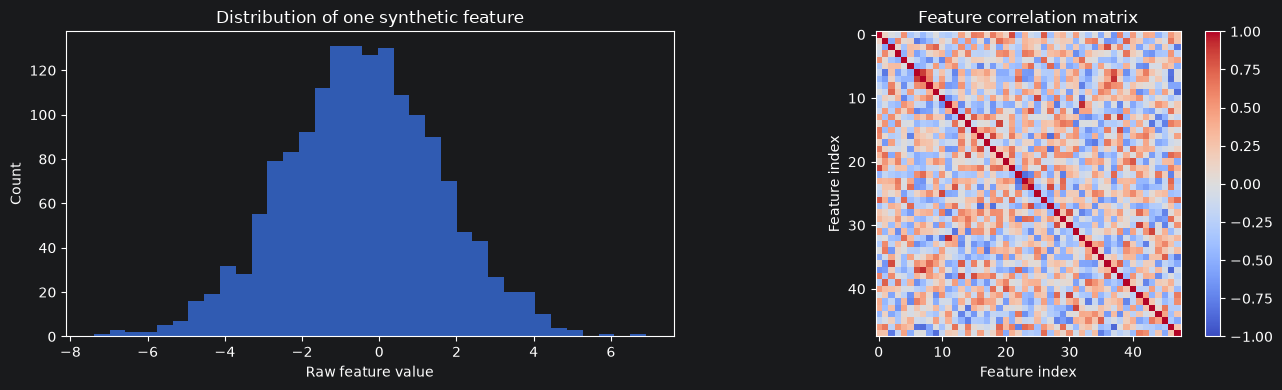

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(X_train_raw[:, 0], bins=35, alpha=0.8)
axes[0].set_title("Distribution of one synthetic feature")
axes[0].set_xlabel("Raw feature value")
axes[0].set_ylabel("Count")

im = axes[1].imshow(np.corrcoef(X_train_raw, rowvar=False), cmap="coolwarm", vmin=-1, vmax=1)
axes[1].set_title("Feature correlation matrix")
axes[1].set_xlabel("Feature index")
axes[1].set_ylabel("Feature index")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## 7. Create anomalies for a held-out evaluation set

An anomaly is generated by applying a strong shift to a small random subset of features. The anomaly-generation code is provided only for evaluation. Do not add these samples to the autoencoder's training data.

In [5]:
def inject_sparse_anomalies(X_normal, random_state, n_affected_features=7):
    local_rng = np.random.default_rng(random_state)
    X_anomaly = X_normal.copy()
    for row in range(len(X_anomaly)):
        affected = local_rng.choice(
            X_anomaly.shape[1], size=n_affected_features, replace=False
        )
        shifts = local_rng.choice([-1.0, 1.0], size=n_affected_features)
        magnitudes = local_rng.uniform(3.5, 5.0, size=n_affected_features)
        X_anomaly[row, affected] += shifts * magnitudes
    return X_anomaly


X_test_anomaly_raw = inject_sparse_anomalies(
    generate_normal_expression(140, SEED + 4), random_state=SEED + 5
)

print("Anomaly test samples:", X_test_anomaly_raw.shape)

Anomaly test samples: (140, 48)


## 8. Leakage-safe scaling and final data preparation

All scaling parameters are estimated from **normal training samples only**. The validation set contains normal samples and is used for model selection and anomaly-threshold calibration. The test set contains both normal and artificial anomalous samples and is used once for final evaluation.

No test data are used to fit the scaler, train the autoencoder, or choose the anomaly threshold.

In [6]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw).astype("float32")
X_val = scaler.transform(X_val_raw).astype("float32")
X_test_normal = scaler.transform(X_test_normal_raw).astype("float32")
X_test_anomaly = scaler.transform(X_test_anomaly_raw).astype("float32")

X_test = np.vstack([X_test_normal, X_test_anomaly]).astype("float32")
y_test_anomaly = np.concatenate([
    np.zeros(len(X_test_normal), dtype="int32"),
    np.ones(len(X_test_anomaly), dtype="int32"),
])

# Shuffle only the held-out test rows; this does not affect model fitting.
test_order = rng.permutation(len(X_test))
X_test = X_test[test_order]
y_test_anomaly = y_test_anomaly[test_order]

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Test anomaly prevalence:", round(float(y_test_anomaly.mean()), 3))
print("Train feature mean (first 5):", np.round(X_train.mean(axis=0)[:5], 3))
print("Train feature std (first 5):", np.round(X_train.std(axis=0)[:5], 3))

X_train: (1600, 48)
X_val: (350, 48)
X_test: (490, 48)
Test anomaly prevalence: 0.286
Train feature mean (first 5): [ 0. -0.  0.  0. -0.]
Train feature std (first 5): [1. 1. 1. 1. 1.]


## 9. Build training pipelines

Autoencoders receive the input as both the model input and reconstruction target. We shuffle and batch training examples, and use a separate non-shuffled validation dataset.

In [7]:
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, X_train))
    .shuffle(buffer_size=len(X_train), seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, X_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for batch_x, batch_y in train_ds.take(1):
    print("Input batch:", batch_x.shape)
    print("Target batch:", batch_y.shape)

Input batch: (64, 48)
Target batch: (64, 48)


# Part I — Basic Autoencoder

## 10. Define the encoder and decoder

We use a 48-dimensional input, a compact hidden representation, and an 8-dimensional bottleneck. Because the standardized features can be negative, the output layer is linear.

In [8]:
INPUT_DIM = X_train.shape[1]
LATENT_DIM = 8

encoder_inputs = keras.Input(shape=(INPUT_DIM,), name="expression_input")
x = layers.Dense(32, activation="relu", name="encoder_dense_1")(encoder_inputs)
x = layers.Dense(16, activation="relu", name="encoder_dense_2")(x)
latent = layers.Dense(LATENT_DIM, activation="linear", name="latent_vector")(x)
encoder = keras.Model(encoder_inputs, latent, name="encoder")

latent_inputs = keras.Input(shape=(LATENT_DIM,), name="latent_input")
x = layers.Dense(16, activation="relu", name="decoder_dense_1")(latent_inputs)
x = layers.Dense(32, activation="relu", name="decoder_dense_2")(x)
reconstruction = layers.Dense(INPUT_DIM, activation="linear", name="reconstruction")(x)
decoder = keras.Model(latent_inputs, reconstruction, name="decoder")

autoencoder_inputs = keras.Input(shape=(INPUT_DIM,), name="autoencoder_input")
autoencoder_outputs = decoder(encoder(autoencoder_inputs))
autoencoder = keras.Model(autoencoder_inputs, autoencoder_outputs, name="basic_autoencoder")

autoencoder.summary()

Model: "basic_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 8)              │         2,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 48)             │         2,272 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,504 (17.59 KB)

 Trainable params: 4,504 (17.59 KB)

 Non-trainable params: 0 (0.00 B)

### Parameter flow

The encoder compresses each sample from 48 values to 8 latent values. The decoder maps those 8 values back to 48 reconstructed values. The model is trained by comparing the reconstruction with the original input.

In [9]:
autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.MeanSquaredError(),
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8, restore_best_weights=True
    )
]

history_ae = autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=60,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/60


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.9898 - mae: 0.7939 - val_loss: 0.9257 - val_mae: 0.7664
Epoch 2/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8977 - mae: 0.7538 - val_loss: 0.8240 - val_mae: 0.7187
Epoch 3/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7879 - mae: 0.7020 - val_loss: 0.7012 - val_mae: 0.6579
Epoch 4/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6454 - mae: 0.6288 - val_loss: 0.5400 - val_mae: 0.5731
Epoch 5/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4665 - mae: 0.5288 - val_loss: 0.3640 - val_mae: 0.4674
Epoch 6/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3146 - mae: 0.4326 - val_loss: 0.2435 - val_mae: 0.3806
Epoch 7/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2157 - mae: 0.3593 - val_loss: 0.1671 - val_mae: 0.3192
Epoch 8/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1469 - mae: 0.2998 - val_loss: 0.1240 - val_mae: 0.2771
Epoch 9/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1153 - mae: 0.2668 - va

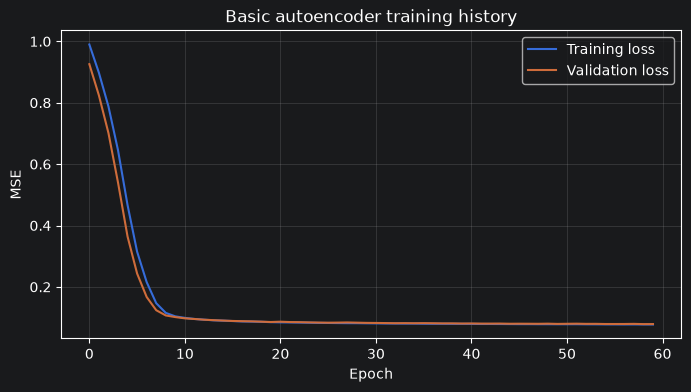

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(history_ae.history["loss"], label="Training loss")
plt.plot(history_ae.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Basic autoencoder training history")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [11]:
X_val_reconstructed = autoencoder.predict(X_val, verbose=0)
val_mse_per_sample = np.mean(np.square(X_val - X_val_reconstructed), axis=1)

print("Validation reconstruction MSE:")
print(pd.Series(val_mse_per_sample).describe(percentiles=[0.50, 0.90, 0.95, 0.99]))

Validation reconstruction MSE:
count    350.000000
mean       0.078681
std        0.019717
min        0.042707
50%        0.076379
90%        0.105070
95%        0.119289
99%        0.134905
max        0.159869
dtype: float64


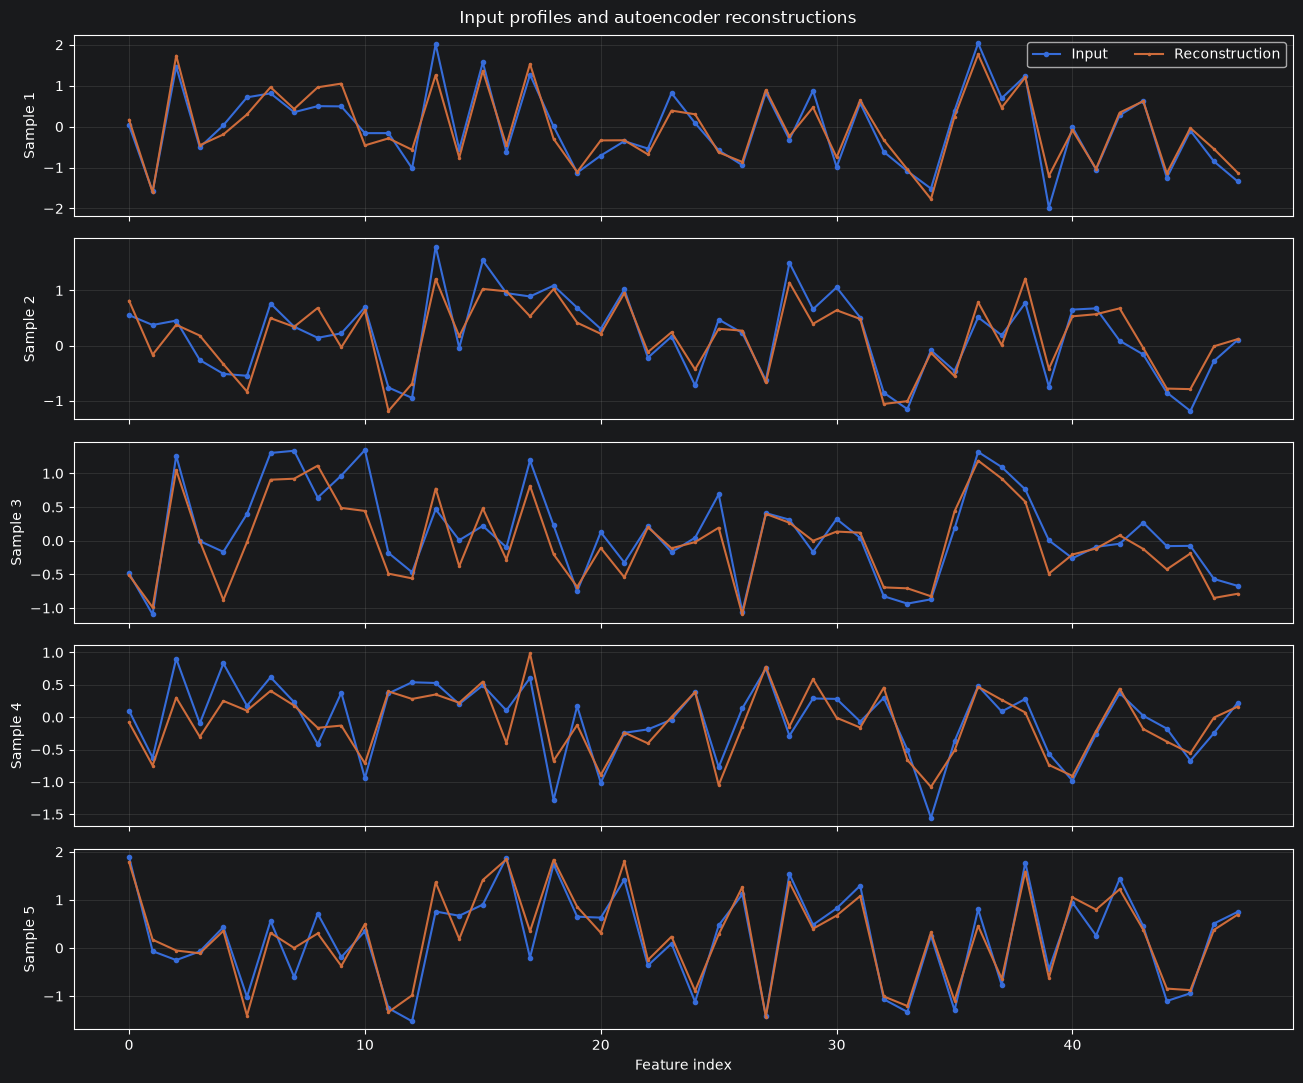

In [12]:
# Compare a few input samples with their reconstructions.
X_demo_reconstructed = autoencoder.predict(X_val[:5], verbose=0)
feature_axis = np.arange(INPUT_DIM)

fig, axes = plt.subplots(5, 1, figsize=(13, 11), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(feature_axis, X_val[i], marker="o", ms=3, label="Input")
    ax.plot(feature_axis, X_demo_reconstructed[i], marker=".", ms=3, label="Reconstruction")
    ax.set_ylabel(f"Sample {i+1}")
    ax.grid(alpha=0.2)
axes[0].legend(ncol=2)
axes[-1].set_xlabel("Feature index")
fig.suptitle("Input profiles and autoencoder reconstructions")
plt.tight_layout()
plt.show()

## 11. Inspect the latent representation

A latent space is a learned representation, not automatically a biological map. For visualization, we can project the 8-dimensional codes to two dimensions with PCA. PCA is applied only to the encoded vectors for plotting; it does not participate in autoencoder training.

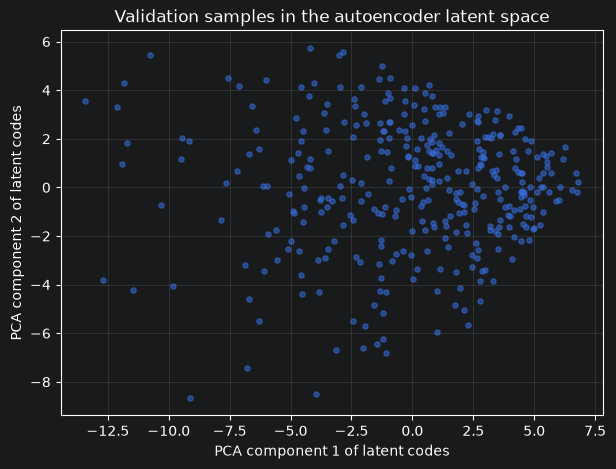

In [13]:
Z_val = encoder.predict(X_val, verbose=0)
Z_val_2d = PCA(n_components=2, random_state=SEED).fit_transform(Z_val)

plt.figure(figsize=(7, 5))
plt.scatter(Z_val_2d[:, 0], Z_val_2d[:, 1], s=14, alpha=0.55)
plt.xlabel("PCA component 1 of latent codes")
plt.ylabel("PCA component 2 of latent codes")
plt.title("Validation samples in the autoencoder latent space")
plt.grid(alpha=0.2)
plt.show()

## 12. Bottleneck capacity experiment

A smaller latent dimension imposes stronger compression but can increase reconstruction error. A larger latent dimension can reconstruct more detail, but may retain nuisance variation and can make anomaly detection less effective if the model reconstructs unusual inputs too well.

The following table is a conceptual guide; the actual trade-off must be measured on held-out validation data.

| Latent dimension | Compression | Typical risk |
|---:|---|---|
| Very small | Strong | Under-reconstruction |
| Moderate | Balanced | May retain useful structure |
| Large | Weak | Near-identity mapping |

# Part II — Sparse Autoencoder

## 13. Encourage sparse latent activations

We add an L1 activity regularizer to the bottleneck layer. This penalizes non-zero latent activations and can encourage a more selective representation. The regularization coefficient is a hyperparameter and should be chosen using validation performance and representation diagnostics.

In [14]:
SPARSE_L1 = 1e-3

sparse_inputs = keras.Input(shape=(INPUT_DIM,), name="sparse_input")
x = layers.Dense(32, activation="relu")(sparse_inputs)
x = layers.Dense(16, activation="relu")(x)
sparse_latent = layers.Dense(
    LATENT_DIM,
    activation="relu",
    activity_regularizer=keras.regularizers.L1(SPARSE_L1),
    name="sparse_latent",
)(x)
sparse_encoder = keras.Model(sparse_inputs, sparse_latent, name="sparse_encoder")

sparse_latent_inputs = keras.Input(shape=(LATENT_DIM,))
x = layers.Dense(16, activation="relu")(sparse_latent_inputs)
x = layers.Dense(32, activation="relu")(x)
sparse_outputs = layers.Dense(INPUT_DIM, activation="linear")(x)
sparse_decoder = keras.Model(sparse_latent_inputs, sparse_outputs, name="sparse_decoder")

sparse_autoencoder_inputs = keras.Input(shape=(INPUT_DIM,))
sparse_autoencoder = keras.Model(
    sparse_autoencoder_inputs,
    sparse_decoder(sparse_encoder(sparse_autoencoder_inputs)),
    name="sparse_autoencoder",
)

sparse_autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
)
sparse_history = sparse_autoencoder.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)],
    verbose=1,
)

Epoch 1/50


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.9900 - val_loss: 0.9407
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9206 - val_loss: 0.8442
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.8167 - val_loss: 0.7529
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.7219 - val_loss: 0.6573
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6158 - val_loss: 0.5653
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.5194 - val_loss: 0.4702
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4219 - val_loss: 0.3790
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3453 - val_loss: 0.3230
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3012 - val_loss: 0.2828
Epoch 10/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2710 - val_loss: 0.2623
Epoch 11/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2573 - val_loss: 0.2496
Epoch 12/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2502 - val_loss: 0.2435


Basic encoder near-zero activation fraction:  0.000
Sparse encoder near-zero activation fraction: 0.208


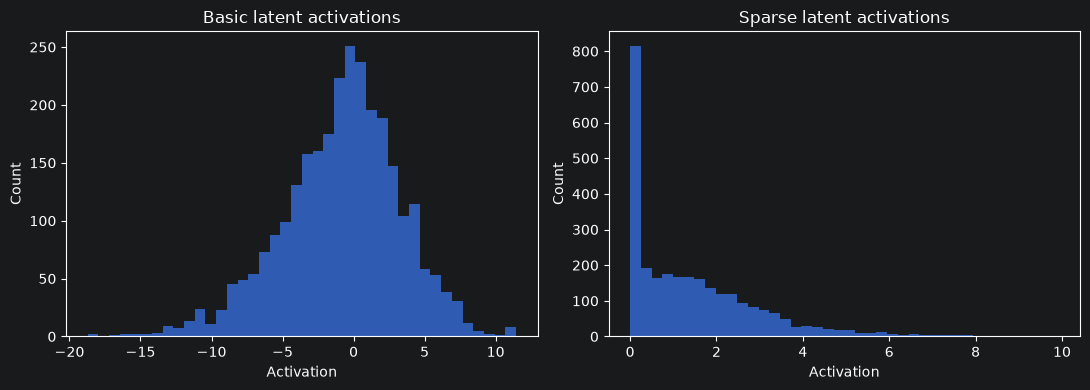

In [15]:
Z_basic = encoder.predict(X_val, verbose=0)
Z_sparse = sparse_encoder.predict(X_val, verbose=0)

basic_zero_fraction = np.mean(np.abs(Z_basic) < 1e-3)
sparse_zero_fraction = np.mean(np.abs(Z_sparse) < 1e-3)

print(f"Basic encoder near-zero activation fraction:  {basic_zero_fraction:.3f}")
print(f"Sparse encoder near-zero activation fraction: {sparse_zero_fraction:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(Z_basic.ravel(), bins=40, alpha=0.8)
axes[0].set_title("Basic latent activations")
axes[1].hist(Z_sparse.ravel(), bins=40, alpha=0.8)
axes[1].set_title("Sparse latent activations")
for ax in axes:
    ax.set_xlabel("Activation")
    ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

# Part III — Denoising Autoencoder

## 14. Corrupt inputs, reconstruct clean targets

The input to the denoising autoencoder is perturbed by Gaussian noise. Its target remains the original clean training sample. The validation inputs are corrupted independently, while the validation targets remain clean.

In [16]:
NOISE_STD = 0.30
noise_rng = np.random.default_rng(SEED + 20)

X_train_noisy = X_train + noise_rng.normal(0.0, NOISE_STD, X_train.shape).astype("float32")
X_val_noisy = X_val + noise_rng.normal(0.0, NOISE_STD, X_val.shape).astype("float32")

print("Clean training shape:", X_train.shape)
print("Noisy training shape:", X_train_noisy.shape)
print("Noise standard deviation:", NOISE_STD)

Clean training shape: (1600, 48)
Noisy training shape: (1600, 48)
Noise standard deviation: 0.3


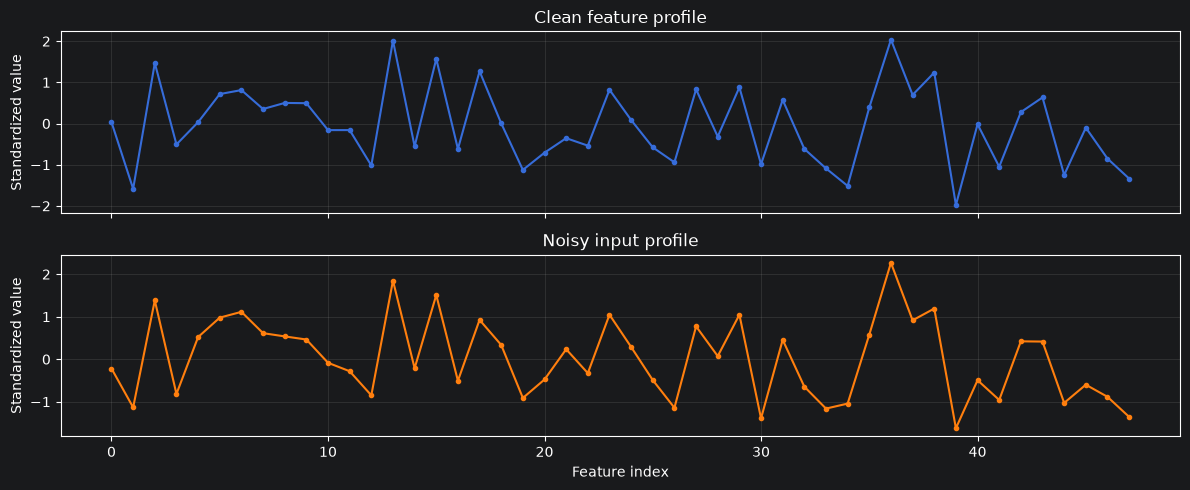

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(X_val[0], marker="o", ms=3)
axes[0].set_title("Clean feature profile")
axes[1].plot(X_val_noisy[0], marker="o", ms=3, color="tab:orange")
axes[1].set_title("Noisy input profile")
axes[1].set_xlabel("Feature index")
for ax in axes:
    ax.set_ylabel("Standardized value")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [18]:
denoise_inputs = keras.Input(shape=(INPUT_DIM,), name="noisy_input")
x = layers.Dense(32, activation="relu")(denoise_inputs)
x = layers.Dense(16, activation="relu")(x)
den_noise_code = layers.Dense(LATENT_DIM, activation="relu", name="denoising_code")(x)
x = layers.Dense(16, activation="relu")(den_noise_code)
x = layers.Dense(32, activation="relu")(x)
den_noise_outputs = layers.Dense(INPUT_DIM, activation="linear")(x)
denoising_autoencoder = keras.Model(denoise_inputs, den_noise_outputs, name="denoising_autoencoder")

denoising_autoencoder.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=[keras.metrics.MeanAbsoluteError(name="mae")],
)

denoise_history = denoising_autoencoder.fit(
    X_train_noisy,
    X_train,
    validation_data=(X_val_noisy, X_val),
    batch_size=BATCH_SIZE,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)],
    verbose=1,
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.9743 - mae: 0.7880 - val_loss: 0.9104 - val_mae: 0.7623
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8665 - mae: 0.7380 - val_loss: 0.7739 - val_mae: 0.6971
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7221 - mae: 0.6681 - val_loss: 0.6273 - val_mae: 0.6239
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5723 - mae: 0.5903 - val_loss: 0.5044 - val_mae: 0.5559
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4703 - mae: 0.5328 - val_loss: 0.4318 - val_mae: 0.5105
Epoch 6/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4051 - mae: 0.4921 - val_loss: 0.3721 - val_mae: 0.4704
Epoch 7/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3532 - mae: 0.4574 - val_loss: 0.3226 - val_mae: 0.4364
Epoch 8/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3107 - mae: 0.4282 - val_loss: 0.2854 - val_mae: 0.4100
Epoch 9/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2840 - mae:

Mean error before denoising: 0.0899
Mean error after denoising:  0.0967


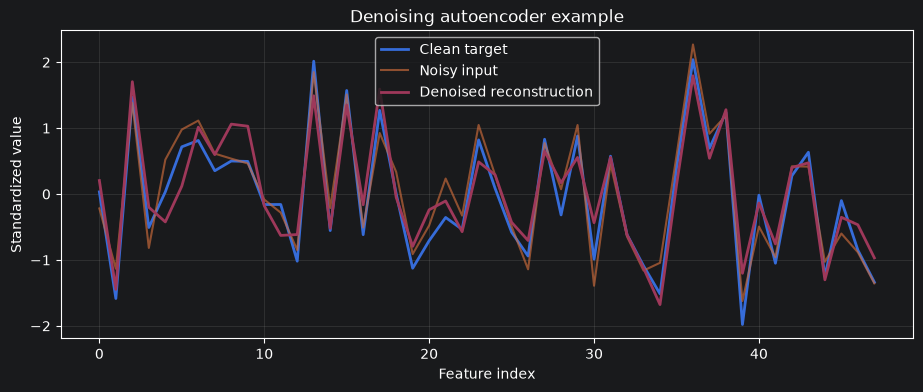

In [19]:
X_val_denoised = denoising_autoencoder.predict(X_val_noisy, verbose=0)
noisy_mse = np.mean(np.square(X_val_noisy - X_val), axis=1)
denoised_mse = np.mean(np.square(X_val_denoised - X_val), axis=1)

print(f"Mean error before denoising: {noisy_mse.mean():.4f}")
print(f"Mean error after denoising:  {denoised_mse.mean():.4f}")

sample_idx = 0
plt.figure(figsize=(11, 4))
plt.plot(X_val[sample_idx], label="Clean target", linewidth=2)
plt.plot(X_val_noisy[sample_idx], label="Noisy input", alpha=0.65)
plt.plot(X_val_denoised[sample_idx], label="Denoised reconstruction", linewidth=2)
plt.xlabel("Feature index")
plt.ylabel("Standardized value")
plt.title("Denoising autoencoder example")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

# Part IV — Variational Autoencoder (VAE)

## 15. From a point code to a probability distribution

The VAE encoder returns three outputs:

- `z_mean`: the mean of the approximate posterior distribution.
- `z_log_var`: the logarithm of its variance.
- `z`: a sample drawn using the reparameterization trick.

The logarithm of the variance is predicted for numerical convenience; exponentiation gives a positive variance.

In [20]:
VAE_LATENT_DIM = 2

class Sampling(layers.Layer):
    """Sample z using the reparameterization trick."""
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


vae_encoder_inputs = keras.Input(shape=(INPUT_DIM,), name="vae_expression_input")
x = layers.Dense(32, activation="relu")(vae_encoder_inputs)
x = layers.Dense(16, activation="relu")(x)
z_mean = layers.Dense(VAE_LATENT_DIM, name="z_mean")(x)
z_log_var = layers.Dense(VAE_LATENT_DIM, name="z_log_var")(x)
z_sample = Sampling(name="latent_sampling")([z_mean, z_log_var])
vae_encoder = keras.Model(
    vae_encoder_inputs, [z_mean, z_log_var, z_sample], name="vae_encoder"
)

vae_decoder_inputs = keras.Input(shape=(VAE_LATENT_DIM,), name="vae_latent_input")
x = layers.Dense(16, activation="relu")(vae_decoder_inputs)
x = layers.Dense(32, activation="relu")(x)
vae_decoder_outputs = layers.Dense(INPUT_DIM, activation="linear")(x)
vae_decoder = keras.Model(vae_decoder_inputs, vae_decoder_outputs, name="vae_decoder")

vae_encoder.summary()
vae_decoder.summary()

Model: "vae_encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ vae_expression_inp… │ (None, 48)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 32)        │      1,568 │ vae_expression_i… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 16)        │        528 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         34 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         34 │ dense_11[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent_sampling     │ (None, 2)         │          0 │ z_mean[0][0],     │
│ (Sampling)          │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,164 (8.45 KB)

 Trainable params: 2,164 (8.45 KB)

 Non-trainable params: 0 (0.00 B)

Model: "vae_decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vae_latent_input (InputLayer)   │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 48)             │         1,584 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,176 (8.50 KB)

 Trainable params: 2,176 (8.50 KB)

 Non-trainable params: 0 (0.00 B)

## 16. Implement the VAE objective with a custom training step

For each sample, the reconstruction term is the sum of squared feature errors. The KL term measures how far the approximate posterior is from the standard normal prior. We average both terms across the batch.

The custom `train_step` makes the two loss components explicit and returns separate metrics for monitoring.

In [21]:
class VariationalAutoencoder(keras.Model):
    def __init__(self, encoder, decoder, beta=1.0, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = keras.metrics.Mean(name="total_loss")
        self.reconstruction_loss_tracker = keras.metrics.Mean(name="reconstruction_loss")
        self.kl_loss_tracker = keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker,
        ]

    def _loss_components(self, x, training=False):
        z_mean, z_log_var, z = self.encoder(x, training=training)
        x_reconstructed = self.decoder(z, training=training)

        reconstruction_per_sample = tf.reduce_sum(
            tf.square(x - x_reconstructed), axis=1
        )
        reconstruction_loss = tf.reduce_mean(reconstruction_per_sample)

        kl_per_sample = -0.5 * tf.reduce_sum(
            1.0 + z_log_var - tf.square(z_mean) - tf.exp(z_log_var), axis=1
        )
        kl_loss = tf.reduce_mean(kl_per_sample)
        total_loss = reconstruction_loss + self.beta * kl_loss
        return total_loss, reconstruction_loss, kl_loss

    def train_step(self, data):
        x, _, _ = keras.utils.unpack_x_y_sample_weight(data)
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self._loss_components(
                x, training=True
            )
        gradients = tape.gradient(total_loss, self.trainable_weights)
        self.optimizer.apply_gradients(
            (gradient, variable)
            for gradient, variable in zip(gradients, self.trainable_weights)
            if gradient is not None
        )
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def test_step(self, data):
        x, _, _ = keras.utils.unpack_x_y_sample_weight(data)
        total_loss, reconstruction_loss, kl_loss = self._loss_components(
            x, training=False
        )
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_loss_tracker.update_state(reconstruction_loss)
        self.kl_loss_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}


vae = VariationalAutoencoder(vae_encoder, vae_decoder, beta=1.0, name="variational_autoencoder")
vae.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3))

In [23]:
vae_history = vae.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    batch_size=BATCH_SIZE,
    epochs=50,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_total_loss",
            mode="min",
            patience=8,
            restore_best_weights=True,
            verbose=1
        )
    ],
    verbose=1,
)

Epoch 1/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - kl_loss: 0.3425 - reconstruction_loss: 47.3149 - total_loss: 47.6574 - val_kl_loss: 0.5298 - val_reconstruction_loss: 45.4092 - val_total_loss: 45.9390
Epoch 2/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - kl_loss: 1.1989 - reconstruction_loss: 43.9672 - total_loss: 45.1661 - val_kl_loss: 1.9433 - val_reconstruction_loss: 40.1237 - val_total_loss: 42.0670
Epoch 3/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 157ms/step - kl_loss: 2.0743 - reconstruction_loss: 39.3856 - total_loss: 41.4599 - val_kl_loss: 2.0358 - val_reconstruction_loss: 37.7975 - val_total_loss: 39.8333
Epoch 4/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - kl_loss: 2.2919 - reconstruction_loss: 37.0461 - total_loss: 39.3380 - val_kl_loss: 2.3337 - val_reconstruction_loss: 35.5795 - val_total_loss: 37.9131
Epoch 5/50
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - kl_loss: 2.7562 - reconstruction_loss: 34.2732 - total_loss: 37.0294 - val_kl_loss: 2.8331 - val_reconstruction_loss: 33.2699 - v

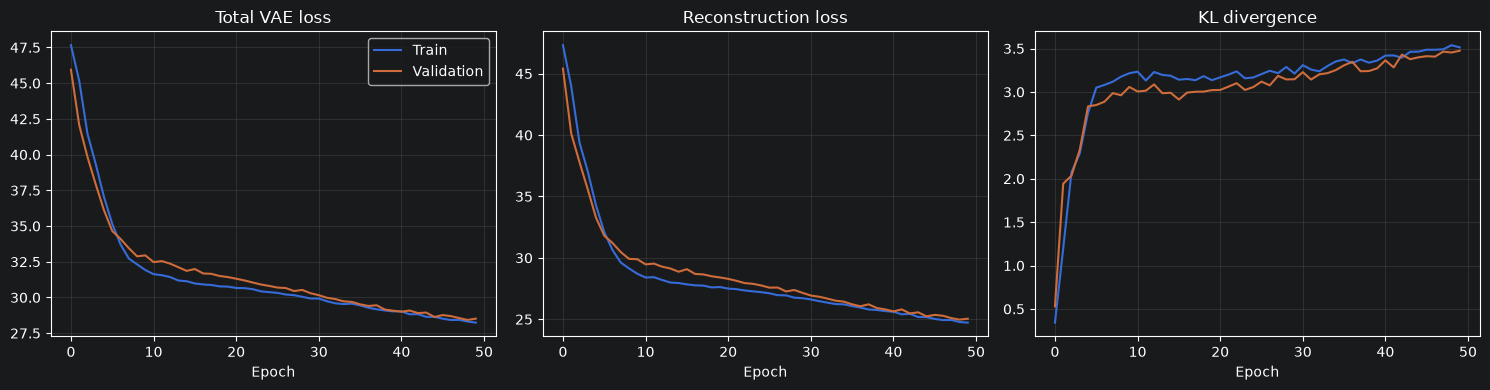

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
metric_pairs = [
    ("total_loss", "val_total_loss", "Total VAE loss"),
    ("reconstruction_loss", "val_reconstruction_loss", "Reconstruction loss"),
    ("kl_loss", "val_kl_loss", "KL divergence"),
]
for ax, (train_key, val_key, title) in zip(axes, metric_pairs):
    ax.plot(vae_history.history[train_key], label="Train")
    ax.plot(vae_history.history[val_key], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.2)
axes[0].legend()
plt.tight_layout()
plt.show()

## 17. Inspect the VAE latent space

The posterior means provide a deterministic summary of each input's approximate latent distribution. We can plot the two latent coordinates and distinguish normal from artificial anomaly samples for inspection. Labels are used only to color this **evaluation visualization**; they are not used for VAE training.

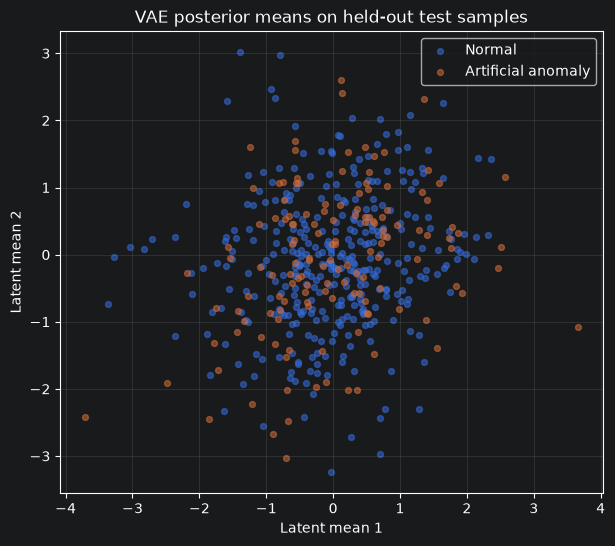

In [25]:
Z_test_mean, Z_test_log_var, Z_test_sample = vae_encoder.predict(X_test, verbose=0)

plt.figure(figsize=(7, 6))
for label, name in [(0, "Normal"), (1, "Artificial anomaly")]:
    mask = y_test_anomaly == label
    plt.scatter(
        Z_test_mean[mask, 0], Z_test_mean[mask, 1],
        s=18, alpha=0.55, label=name
    )
plt.xlabel("Latent mean 1")
plt.ylabel("Latent mean 2")
plt.title("VAE posterior means on held-out test samples")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

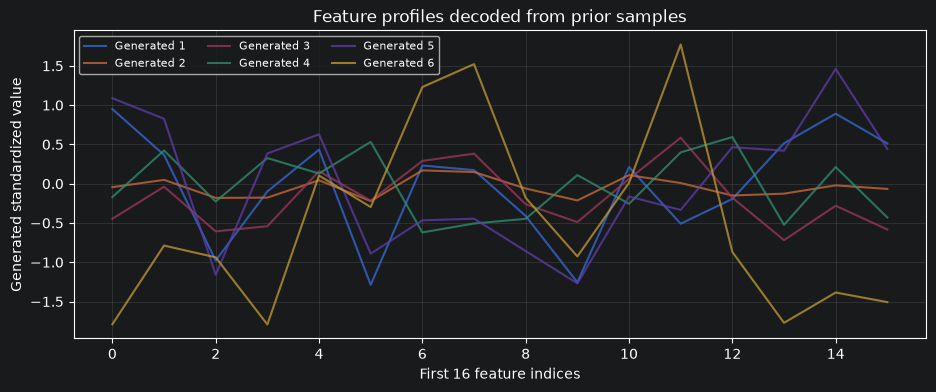

In [26]:
# Sample from the standard normal prior and decode synthetic feature profiles.
N_GENERATED = 12
z_prior = rng.normal(size=(N_GENERATED, VAE_LATENT_DIM)).astype("float32")
X_generated = vae_decoder.predict(z_prior, verbose=0)

plt.figure(figsize=(11, 4))
for i in range(min(6, N_GENERATED)):
    plt.plot(X_generated[i, :16], alpha=0.75, label=f"Generated {i+1}")
plt.xlabel("First 16 feature indices")
plt.ylabel("Generated standardized value")
plt.title("Feature profiles decoded from prior samples")
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=0.2)
plt.show()

# Part V — Reconstruction-Based Anomaly Detection

## 18. Why reconstruction error can indicate an anomaly

An autoencoder trained mainly on normal samples may reconstruct familiar patterns more accurately than unusual patterns. A per-sample reconstruction score can be defined as

$$
e_i = \frac{1}{d}\sum_{j=1}^{d}(x_{ij}-\hat{x}_{ij})^2
$$

A threshold $\tau$ converts the continuous score to a binary decision:

$$
\hat{y}_i = \mathbb{1}[e_i > \tau]
$$

This is a heuristic, not a universal property of autoencoders. Anomalies that resemble the training distribution may have low reconstruction error, while valid but rare normal samples may have high error.

## 19. Calibrate the threshold using normal validation data

We use the 99th percentile of **normal validation reconstruction errors** as an illustrative threshold. The percentile is a design choice, not a universal default. In practice, it should reflect operational constraints, expected false-alarm rates, and independent validation data representative of deployment conditions.

In [27]:
# Use the basic autoencoder trained only on normal training samples.
X_val_recon_for_threshold = autoencoder.predict(X_val, verbose=0)
val_normal_errors = np.mean(
    np.square(X_val - X_val_recon_for_threshold), axis=1
)

THRESHOLD_QUANTILE = 0.99
anomaly_threshold = float(np.quantile(val_normal_errors, THRESHOLD_QUANTILE))
print(f"Threshold quantile: {THRESHOLD_QUANTILE:.3f}")
print(f"Calibrated threshold: {anomaly_threshold:.5f}")

Threshold quantile: 0.990
Calibrated threshold: 0.13490


In [28]:
X_test_reconstructed = autoencoder.predict(X_test, verbose=0)
test_reconstruction_errors = np.mean(
    np.square(X_test - X_test_reconstructed), axis=1
)
y_pred_anomaly = (test_reconstruction_errors > anomaly_threshold).astype("int32")

cm = confusion_matrix(y_test_anomaly, y_pred_anomaly, labels=[0, 1])
precision = precision_score(y_test_anomaly, y_pred_anomaly, zero_division=0)
recall = recall_score(y_test_anomaly, y_pred_anomaly, zero_division=0)
f1 = f1_score(y_test_anomaly, y_pred_anomaly, zero_division=0)
roc_auc = roc_auc_score(y_test_anomaly, test_reconstruction_errors)
average_precision = average_precision_score(y_test_anomaly, test_reconstruction_errors)

print("Confusion matrix [normal, anomaly]:\n", cm)
print(f"Precision:         {precision:.3f}")
print(f"Recall:            {recall:.3f}")
print(f"F1-score:          {f1:.3f}")
print(f"ROC-AUC:           {roc_auc:.3f}")
print(f"Average precision: {average_precision:.3f}")
print("\nClassification report:")
print(classification_report(
    y_test_anomaly, y_pred_anomaly,
    target_names=["normal", "anomaly"], zero_division=0
))

Confusion matrix [normal, anomaly]:
 [[347   3]
 [  0 140]]
Precision:         0.979
Recall:            1.000
F1-score:          0.989
ROC-AUC:           1.000
Average precision: 1.000

Classification report:
              precision    recall  f1-score   support

      normal       1.00      0.99      1.00       350
     anomaly       0.98      1.00      0.99       140

    accuracy                           0.99       490
   macro avg       0.99      1.00      0.99       490
weighted avg       0.99      0.99      0.99       490



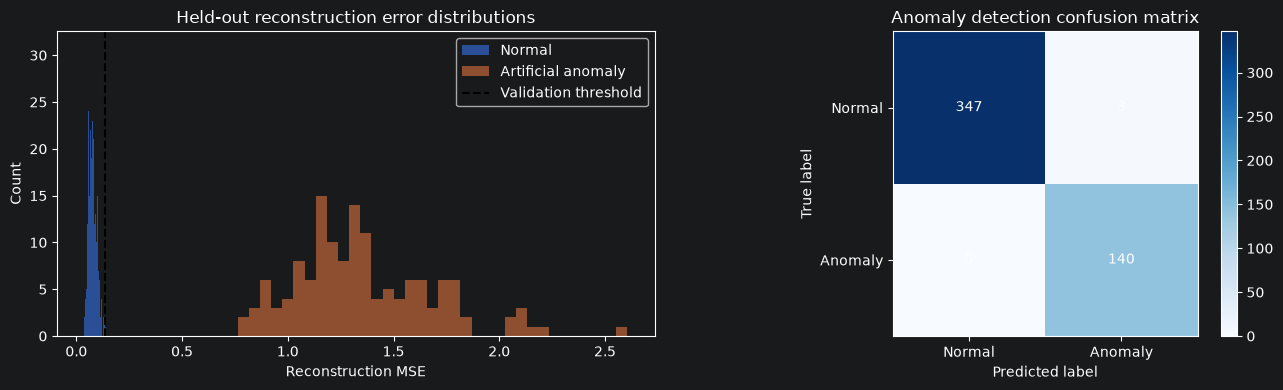

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(
    test_reconstruction_errors[y_test_anomaly == 0],
    bins=35, alpha=0.65, label="Normal"
)
axes[0].hist(
    test_reconstruction_errors[y_test_anomaly == 1],
    bins=35, alpha=0.65, label="Artificial anomaly"
)
axes[0].axvline(anomaly_threshold, color="black", linestyle="--", label="Validation threshold")
axes[0].set_xlabel("Reconstruction MSE")
axes[0].set_ylabel("Count")
axes[0].set_title("Held-out reconstruction error distributions")
axes[0].legend()

im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_title("Anomaly detection confusion matrix")
axes[1].set_xlabel("Predicted label")
axes[1].set_ylabel("True label")
axes[1].set_xticks([0, 1], ["Normal", "Anomaly"])
axes[1].set_yticks([0, 1], ["Normal", "Anomaly"])
for (i, j), value in np.ndenumerate(cm):
    axes[1].text(j, i, str(value), ha="center", va="center")
fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

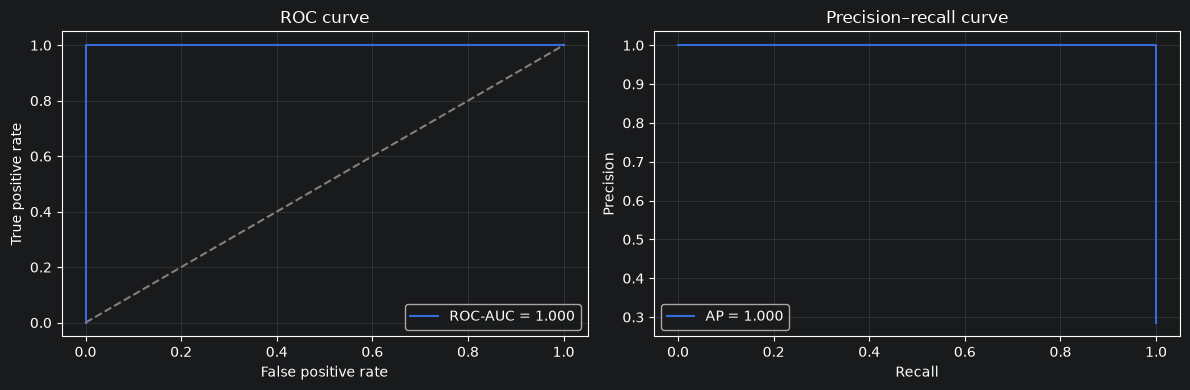

In [30]:
fpr, tpr, _ = roc_curve(y_test_anomaly, test_reconstruction_errors)
pr_precision, pr_recall, _ = precision_recall_curve(
    y_test_anomaly, test_reconstruction_errors
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curve")
axes[0].legend()

axes[1].plot(pr_recall, pr_precision, label=f"AP = {average_precision:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curve")
axes[1].legend()
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 20. Inspect feature-level reconstruction errors

The following visualization summarizes which features contribute most to the average reconstruction error for normal and artificial anomalous test samples. This is descriptive error analysis, **not** causal attribution, feature importance, or a clinical explanation.

In [31]:
normal_mask = y_test_anomaly == 0
anomaly_mask = y_test_anomaly == 1

normal_feature_error = np.mean(
    np.square(X_test[normal_mask] - X_test_reconstructed[normal_mask]), axis=0
)
anomaly_feature_error = np.mean(
    np.square(X_test[anomaly_mask] - X_test_reconstructed[anomaly_mask]), axis=0
)

feature_error_table = pd.DataFrame({
    "feature": feature_names,
    "normal_mean_squared_error": normal_feature_error,
    "anomaly_mean_squared_error": anomaly_feature_error,
})
feature_error_table["error_difference"] = (
    feature_error_table["anomaly_mean_squared_error"]
    - feature_error_table["normal_mean_squared_error"]
)
feature_error_table = feature_error_table.sort_values(
    "error_difference", ascending=False
)
display(feature_error_table.head(12))

,feature,normal_mean_squared_error,anomaly_mean_squared_error,error_difference
17,gene_17,0.170675,3.752451,3.581776
9,gene_09,0.185326,2.976320,2.790994
39,gene_39,0.141880,2.849919,2.708038
5,gene_05,0.214942,2.804511,2.589569
33,gene_33,0.109337,2.654578,2.545241
44,gene_44,0.136688,2.626023,2.489335
15,gene_15,0.143773,2.207185,2.063412
29,gene_29,0.130282,2.086542,1.956261
10,gene_10,0.080911,1.956152,1.875241
3,gene_03,0.080919,1.515257,1.434338


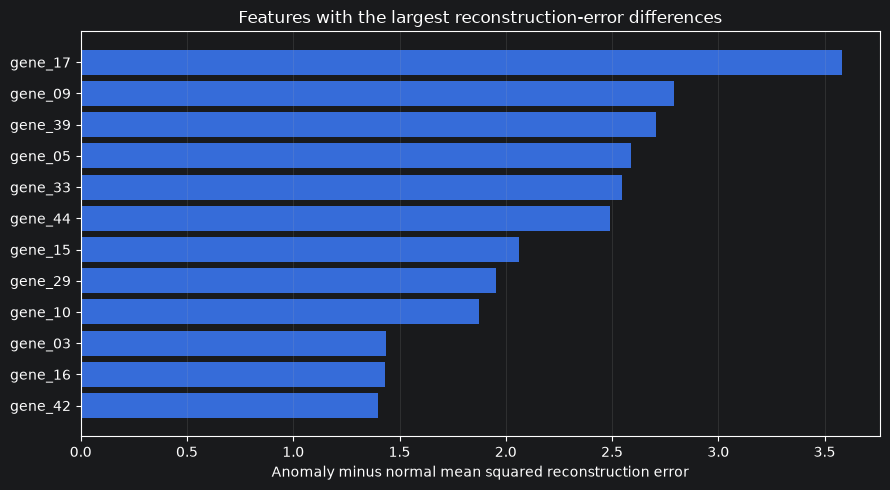

In [32]:
top_features = feature_error_table.head(12).sort_values("error_difference")
plt.figure(figsize=(9, 5))
plt.barh(top_features["feature"], top_features["error_difference"])
plt.xlabel("Anomaly minus normal mean squared reconstruction error")
plt.title("Features with the largest reconstruction-error differences")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

## 21. Choosing and reporting an anomaly threshold

A threshold should be calibrated using data that are separate from the final test set. Several choices are possible:

- A fixed upper quantile of normal validation scores.
- A threshold chosen from a validation set containing representative labeled anomalies, when such labels are legitimately available.
- A domain-defined operating point based on an acceptable false-positive rate.

Never select a threshold after inspecting test labels and then report the same test metrics as an unbiased final estimate. If the deployment distribution changes, threshold calibration may need to be revisited using an appropriate monitoring and validation protocol.

## 22. Important limitations

1. **Reconstruction is not density estimation.** Low reconstruction error does not prove that a sample is probable under the data distribution.
2. **Anomalies may be reconstructed well.** A powerful autoencoder can learn to reconstruct out-of-distribution examples.
3. **Rare normal observations may be flagged.** High reconstruction error is not synonymous with error, disease, or danger.
4. **Thresholds depend on context.** The validation quantile, contamination, feature scaling, and operational costs all affect performance.
5. **Synthetic data are simplified.** The artificial anomalies in this notebook are deliberately injected shifts. Real biological anomalies can be subtle, multivariate, and confounded by batch effects.
6. **Latent dimensions are not automatically interpretable.** Biological interpretation requires independent evidence and careful validation.

# Part VI — Saving, Exercises, and Summary

## 23. Save and reload a trained model

Keras' native `.keras` format is recommended for saving a complete Keras model. The VAE uses a custom subclass and custom training logic; when saving it, the custom class definition must be available when reloading. For a portable inference artifact, saving the encoder and decoder separately can be simpler.

In [33]:
from pathlib import Path

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

autoencoder.save(ARTIFACT_DIR / "basic_autoencoder.keras")
encoder.save(ARTIFACT_DIR / "basic_encoder.keras")
decoder.save(ARTIFACT_DIR / "basic_decoder.keras")

reloaded_autoencoder = keras.models.load_model(ARTIFACT_DIR / "basic_autoencoder.keras")
example_reconstruction = reloaded_autoencoder.predict(X_val[:3], verbose=0)
print("Reloaded model output shape:", example_reconstruction.shape)

Reloaded model output shape: (3, 48)


## 24. Exercises

### Conceptual questions

1. Why is an autoencoder described as self-supervised rather than purely unsupervised in some learning taxonomies?
2. What can happen if the latent dimension is almost as large as the input dimension and the model has high capacity?
3. How does an activity regularizer encourage sparse latent codes?
4. Why does a denoising autoencoder use a corrupted input but a clean reconstruction target?
5. What is the role of the KL-divergence term in a VAE?
6. Why does the VAE reparameterization trick make gradient-based optimization possible?
7. Why should the anomaly threshold be calibrated on validation data rather than the test set?
8. Give two reasons why a normal observation might receive a high reconstruction error.

### Coding exercises

1. Train autoencoders with latent dimensions 2, 4, 8, and 16. Compare training and validation reconstruction errors.
2. Replace MSE with MAE and compare the distribution of per-sample reconstruction errors.
3. Vary the sparse activity penalty over at least three values and inspect the near-zero activation fraction.
4. Vary the denoising noise standard deviation and evaluate reconstruction on a fixed, independently generated noisy validation set.
5. Compare VAE latent dimensions 2 and 4, keeping the data split and evaluation protocol unchanged.
6. Compare 95th, 97.5th, and 99th percentile thresholds using validation-normal scores. Report the resulting test metrics without tuning on test labels.
7. Design a more realistic anomaly generator and explain how its assumptions differ from the sparse feature shifts used here.

### Optional extension

Replace the dense autoencoder with a one-dimensional convolutional autoencoder if features have a meaningful spatial or sequential order. Do not apply convolution to arbitrary tabular columns unless their ordering has a defensible meaning.

## 25. Key takeaways

- An autoencoder learns a representation by reconstructing its input.
- The encoder, bottleneck, and decoder define the core architecture.
- Undercomplete, sparse, and denoising objectives constrain the representation in different ways.
- A VAE learns a distribution in latent space and combines reconstruction loss with KL-divergence regularization.
- Reconstruction error can be a useful anomaly score, but threshold calibration and independent evaluation are essential.
- Data scaling must be fit on training data only, and test samples must not influence training or threshold selection.
- Synthetic examples demonstrate mechanics; they do not establish biological or clinical validity.

## References and further reading

1. TensorFlow, **Intro to Autoencoders**: https://www.tensorflow.org/tutorials/generative/autoencoder
2. Keras, **Variational AutoEncoder example**: https://keras.io/examples/generative/vae/
3. Keras, **Layer weight regularizers**: https://keras.io/api/layers/regularizers/
4. Hinton, G. E., & Salakhutdinov, R. R. (2006). *Reducing the Dimensionality of Data with Neural Networks*. Science, 313(5786), 504–507. https://doi.org/10.1126/science.1127647
5. Vincent, P., et al. (2008). *Extracting and Composing Robust Features with Denoising Autoencoders*. ICML. https://doi.org/10.1145/1390156.1390294
6. Kingma, D. P., & Welling, M. (2014). *Auto-Encoding Variational Bayes*. https://arxiv.org/abs/1312.6114

---

**End of Notebook 11 — Autoencoders and Unsupervised Deep Learning**